# Exploratory data analysis of the ShallKnow benchmarks

The ShallKnow paper evaluates on three fact-checking benchmarks: **BPDP**, **FactBench Mix** and **FAVEL-DS**
(Table 1 in the paper). All three are published on [Zenodo](https://zenodo.org/records/15390036) already mapped to Wikidata.
Each benchmark is a set of reified RDF statements `(subject, predicate, object)` with a truth label (1.0 = true, 0.0 = false).

In this notebook we look at:

1. whether the published files match the paper (sizes, label balance) and whether they are usable,
2. predicates and entities, and how the false statements were generated,
3. how well the entities are covered by English Wikipedia, which ShallKnow uses as its text corpus,
4. how many LLM calls the ShallKnow pipeline needs per dataset (this matters for us, because we want to run it several times with different models),
5. whether the Wikipedia text actually contains evidence for the statements.

Run `tools/download_data.sh` first. Responses from the Wikidata / Wikipedia APIs are cached in `data/cache/`, so only the first run talks to the network (a few minutes).

In [1]:
import json
import random
import re
import time
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from rdflib import Graph, URIRef
from rdflib.namespace import RDF

ROOT = Path("..")
RAW = ROOT / "data" / "raw"
CACHE = ROOT / "data" / "cache"
FIG = Path("figures")
CACHE.mkdir(parents=True, exist_ok=True)
FIG.mkdir(exist_ok=True)

FILES = {
    ("BPDP", "train"): "BPDP_train_reified_wikidata_final.ttl",
    ("BPDP", "test"): "BPDP_test_reified_wikidata_final.ttl",
    ("FactBench", "train"): "Factbench_train_final.ttl",
    ("FactBench", "test"): "Factbench_test_final.ttl",
    ("FAVEL-DS", "train"): "Favel_train_combined.ttl",
    ("FAVEL-DS", "test"): "Favel_test_combined.ttl",
}
# Table 1 of the paper: (true, false, total)
PAPER = {
    ("BPDP", "train"): (100, 100, 200), ("BPDP", "test"): (103, 103, 206),
    ("FactBench", "train"): (633, 486, 1119), ("FactBench", "test"): (637, 492, 1129),
    ("FAVEL-DS", "train"): (380, 385, 765), ("FAVEL-DS", "test"): (163, 164, 327),
}

# colours: one per dataset, plus true/false
C = {"BPDP": "#2a78d6", "FactBench": "#eb6834", "FAVEL-DS": "#1baf7a"}
C_TRUE, C_FALSE, C_GREY = "#2a78d6", "#eb6834", "#b8b7b2"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b2a", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})

## 1. Loading the data

Every statement is identified by its IRI, e.g. `http://swc2017.aksw.org/task2/dataset/stmt_137`, and should have exactly one
subject, predicate, object and truth value. We group the triples by statement IRI and mark a statement as **clean** if that holds.

In [2]:
TV = URIRef("http://swc2017.aksw.org/hasTruthValue")
WD = "http://www.wikidata.org/entity/"
WDT = "http://www.wikidata.org/prop/direct/"


def load_benchmark(path):
    g = Graph()
    g.parse(path, format="nt")
    rows = []
    for stmt in set(g.subjects()):
        s = [str(x) for x in g.objects(stmt, RDF.subject)]
        p = [str(x) for x in g.objects(stmt, RDF.predicate)]
        o = [str(x) for x in g.objects(stmt, RDF.object)]
        tv = [float(x) for x in g.objects(stmt, TV)]
        clean = len(s) == len(p) == len(o) == len(tv) == 1
        rows.append({
            "stmt": str(stmt).rsplit("/", 1)[-1],
            "subject": s[0].replace(WD, "") if clean else None,
            "predicate": p[0].replace(WDT, "") if clean else None,
            "object": o[0].replace(WD, "") if clean else None,
            "label": tv[0] if clean else None,
            "clean": clean,
            "n_subjects": len(s), "n_objects": len(o), "n_labels": len(tv),
        })
    return pd.DataFrame(rows)


frames = []
for (ds, split), fname in FILES.items():
    d = load_benchmark(RAW / fname)
    d["dataset"], d["split"] = ds, split
    frames.append(d)
# sorted, so that sampling with a fixed seed picks the same statements on every run
raw = pd.concat(frames).sort_values(["dataset", "split", "stmt"]).reset_index(drop=True)
raw.head()

,stmt,subject,predicate,object,label,clean,n_subjects,n_objects,n_labels,dataset,split
0,stmt_0,Q46602,P19,Q3426,1.0,True,1,1,1,BPDP,test
1,stmt_1,Q9685,P19,Q2006803,1.0,True,1,1,1,BPDP,test
2,stmt_10,Q76802,P19,Q53746,1.0,True,1,1,1,BPDP,test
3,stmt_100,Q42,P19,Q159288,0.0,True,1,1,1,BPDP,test
4,stmt_101,Q46602,P19,Q90,0.0,True,1,1,1,BPDP,test


### Do the files match the paper?

In [3]:
rows = []
for (ds, split), (pt, pf, ptot) in PAPER.items():
    d = raw[(raw.dataset == ds) & (raw.split == split)]
    c = d[d.clean]
    rows.append({
        "dataset": ds, "split": split,
        "paper total": ptot, "paper T/F": f"{pt}/{pf}",
        "statement IRIs in file": len(d), "clean": len(c),
        "clean T/F": f"{int((c.label == 1).sum())}/{int((c.label == 0).sum())}",
    })
compare = pd.DataFrame(rows)
compare

,dataset,split,paper total,paper T/F,statement IRIs in file,clean,clean T/F
0,BPDP,train,200,100/100,200,200,100/100
1,BPDP,test,206,103/103,206,206,103/103
2,FactBench,train,1119,633/486,680,335,309/26
3,FactBench,test,1129,637/492,684,335,306/29
4,FAVEL-DS,train,765,380/385,765,765,380/385
5,FAVEL-DS,test,327,163/164,327,327,163/164


In [4]:
fb = raw[raw.dataset == "FactBench"]
print("FactBench statements with more than one subject/object/label:", int((~fb.clean).sum()), "of", len(fb))
print("labels per merged statement:", Counter(fb.loc[~fb.clean, "n_labels"]))

# one example of a merged statement
g = Graph(); g.parse(RAW / FILES[("FactBench", "test")], format="nt")
ex = URIRef("http://swc2017.aksw.org/task2/dataset/birth_00005.ttl")
for p, o in sorted(g.predicate_objects(ex)):
    print(f"  {str(p).rsplit('/', 1)[-1].split('#')[-1]:15} {o}")

FactBench statements with more than one subject/object/label: 694 of 1364
labels per merged statement: Counter({2: 679, 1: 15})
  hasTruthValue   0.0
  hasTruthValue   1.0
  object          http://www.wikidata.org/entity/Q24826
  predicate       http://www.wikidata.org/prop/direct/P19
  subject         http://www.wikidata.org/entity/Q228909
  subject         http://www.wikidata.org/entity/Q2599
  type            http://www.w3.org/1999/02/22-rdf-syntax-ns#Statement


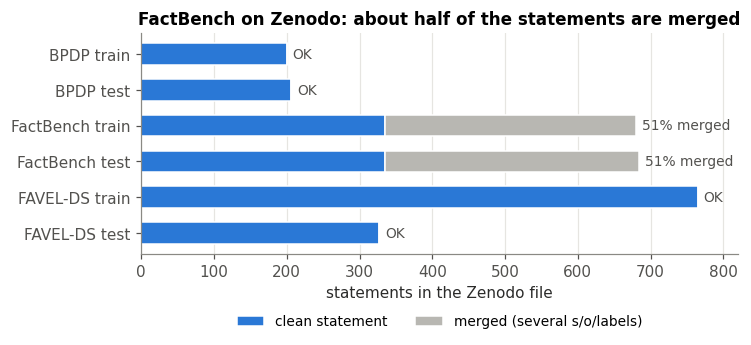

In [5]:
fig, ax = plt.subplots(figsize=(7, 2.6))
labels, clean_n, broken_n = [], [], []
for (ds, split) in FILES:
    d = raw[(raw.dataset == ds) & (raw.split == split)]
    labels.append(f"{ds} {split}")
    clean_n.append(int(d.clean.sum()))
    broken_n.append(int((~d.clean).sum()))
y = np.arange(len(labels))[::-1]
ax.barh(y, clean_n, color=C_TRUE, height=0.6, label="clean statement", edgecolor="white", linewidth=1)
ax.barh(y, broken_n, left=clean_n, color=C_GREY, height=0.6, label="merged (several s/o/labels)", edgecolor="white", linewidth=1)
for yi, cn, bn in zip(y, clean_n, broken_n):
    ax.text(cn + bn + 8, yi, f"{bn / (cn + bn):.0%} merged" if bn else "OK", va="center", fontsize=9, color="#52514e")
ax.set_yticks(y, labels)
ax.set_xlabel("statements in the Zenodo file")
ax.set_title("FactBench on Zenodo: about half of the statements are merged")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 820)
fig.savefig(FIG / "01_file_integrity.png")
plt.show()

**Finding 1: the FactBench files are broken.** In the original FactBench the true and the false statements live in two folders
(`correct/` and `wrong/`) with the *same file names*, e.g. `birth_00005.ttl` exists in both. The file names were used as statement IRIs,
so the true and the false version ended up under one IRI with two subjects, two objects and two truth values, and it is no longer
possible to tell which subject belongs to which object. Only ~335 statements per split are intact, and almost all of them are true
(the false ones are exactly the ones that collided). BPDP and FAVEL-DS are clean and match Table 1 exactly.

**Decision:** we use **FAVEL-DS** as the main dataset and **BPDP** as a small dataset for quick tests. FactBench is left out
(it could be rebuilt from the original DBpedia version, but that is outside the scope of this project).
From here on we work with clean statements only and mostly with BPDP and FAVEL-DS.

In [6]:
df = raw[raw.clean & raw.dataset.isin(["BPDP", "FAVEL-DS"])].copy()
df["label"] = df.label.astype(int)
MAIN = ["BPDP", "FAVEL-DS"]
df.groupby(["dataset", "split", "label"]).size().unstack()

label             0    1
dataset  split          
BPDP     test   103  103
         train  100  100
FAVEL-DS test   164  163
         train  385  380

## 2. Wikidata and Wikipedia lookups

To talk about predicates and entities we need their names, and for the Wikipedia part we need the English article of each entity.
The helpers below call the public APIs politely (custom User-Agent, small delay, retries) and cache everything on disk.

In [7]:
HEADERS = {"User-Agent": "no-need-to-be-so-big/0.1 (university project; https://github.com/ZiarnoM/no-need-to-be-so-big)"}
WIKIDATA_API = "https://www.wikidata.org/w/api.php"
WIKIPEDIA_API = "https://en.wikipedia.org/w/api.php"
session = requests.Session()
session.headers.update(HEADERS)


def api_get(url, params, tries=5):
    for i in range(tries):
        time.sleep(0.2)
        try:
            r = session.get(url, params={"format": "json", **params}, timeout=60)
            if r.status_code == 200:
                return r.json()
        except (requests.RequestException, ValueError):
            pass
        time.sleep(2 ** i)
    raise RuntimeError(f"API call failed: {params}")


class Cache(dict):
    def __init__(self, name):
        self.path = CACHE / f"{name}.json"
        super().__init__(json.loads(self.path.read_text()) if self.path.exists() else {})

    def save(self):
        self.path.write_text(json.dumps(self))


def wikidata_entities(ids):
    # English label + English Wikipedia title for Q-ids and P-ids
    cache = Cache("wikidata_entities")
    todo = sorted(set(ids) - cache.keys())
    for i in range(0, len(todo), 50):
        data = api_get(WIKIDATA_API, {"action": "wbgetentities", "ids": "|".join(todo[i:i + 50]),
                                      "props": "labels|sitelinks", "languages": "en", "sitefilter": "enwiki"})
        for eid, ent in data.get("entities", {}).items():
            cache[eid] = {
                "label": ent.get("labels", {}).get("en", {}).get("value"),
                "enwiki": ent.get("sitelinks", {}).get("enwiki", {}).get("title"),
            }
        cache.save()
    return {i: cache.get(i, {"label": None, "enwiki": None}) for i in ids}


def article_lengths(titles):
    # article size in bytes of wikitext
    cache = Cache("wiki_length")
    todo = sorted(set(titles) - cache.keys())
    for i in range(0, len(todo), 50):
        batch = todo[i:i + 50]
        data = api_get(WIKIPEDIA_API, {"action": "query", "prop": "info", "redirects": 1, "titles": "|".join(batch)})
        q = data.get("query", {})
        back = {t: t for t in batch}
        for n in q.get("normalized", []) + q.get("redirects", []):
            back[n["to"]] = back.get(n["from"], n["from"])
        for page in q.get("pages", {}).values():
            cache[back.get(page["title"], page["title"])] = page.get("length", 0)
        cache.save()
    return {t: cache.get(t) for t in titles}


def outgoing_links(title):
    # number of links to other articles (namespace 0); the ShallKnow script calls the LLM once per linked page
    cache = Cache("wiki_links")
    if title not in cache:
        params, n = {"action": "query", "prop": "links", "plnamespace": 0, "pllimit": "max", "redirects": 1, "titles": title}, 0
        while True:
            data = api_get(WIKIPEDIA_API, params)
            for page in data.get("query", {}).get("pages", {}).values():
                n += len(page.get("links", []))
            if "continue" not in data:
                break
            params.update(data["continue"])
        cache[title] = n
        cache.save()
    return cache[title]


def article_text(title):
    cache = Cache("wiki_text")
    if title not in cache:
        data = api_get(WIKIPEDIA_API, {"action": "query", "prop": "extracts", "explaintext": 1, "redirects": 1, "titles": title})
        pages = data.get("query", {}).get("pages", {})
        cache[title] = next(iter(pages.values()), {}).get("extract", "") if pages else ""
        cache.save()
    return cache[title]

In [8]:
entity_ids = sorted(set(df.subject) | set(df.object))
pred_ids = sorted(set(df.predicate))
info = wikidata_entities(entity_ids + pred_ids)

df["pred_label"] = df.predicate.map(lambda p: f"{info[p]['label']} ({p})")
df["subj_label"] = df.subject.map(lambda q: info[q]["label"] or q)
df["obj_label"] = df.object.map(lambda q: info[q]["label"] or q)
df["subj_wiki"] = df.subject.map(lambda q: info[q]["enwiki"])
df["obj_wiki"] = df.object.map(lambda q: info[q]["enwiki"])
print(len(entity_ids), "entities,", len(pred_ids), "predicates")

1411 entities, 11 predicates


## 3. Predicates

BPDP only has two relations: place of birth and place of death. FAVEL-DS is much more varied.

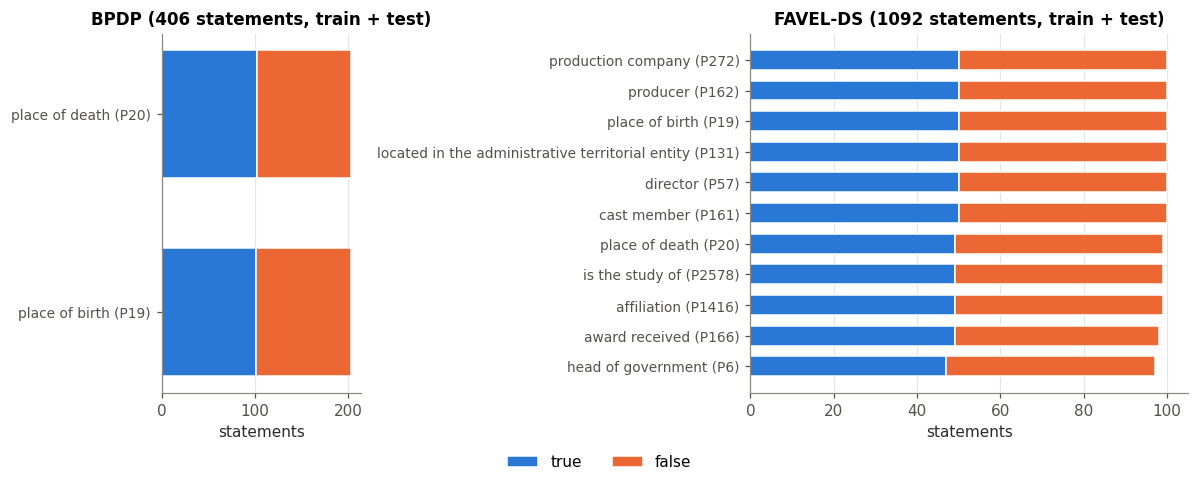

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})
pred_stats = {}
for ax, ds in zip(axes, MAIN):
    d = df[df.dataset == ds]
    t = d.groupby(["pred_label", "label"]).size().unstack(fill_value=0).reindex(columns=[1, 0], fill_value=0)
    t = t.loc[t.sum(axis=1).sort_values().index]
    pred_stats[ds] = t
    y = np.arange(len(t))
    ax.barh(y, t[1], color=C_TRUE, height=0.65, label="true", edgecolor="white", linewidth=1)
    ax.barh(y, t[0], left=t[1], color=C_FALSE, height=0.65, label="false", edgecolor="white", linewidth=1)
    ax.set_yticks(y, t.index, fontsize=9)
    ax.set_title(f"{ds} ({len(d)} statements, train + test)")
    ax.set_xlabel("statements")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", bbox_to_anchor=(0.5, -0.06), ncol=2)
fig.savefig(FIG / "02_predicates.png")
plt.show()

Both datasets are balanced per predicate (roughly as many false as true statements for each relation), so a model cannot just learn
"this relation is usually true". FAVEL-DS covers 11 relations of different kinds: people (birth/death place, spouse, award),
organisations (headquarters, founder, subsidiary) and creative works (author, cast member).

## 4. Entities and how the false statements were made

A false statement is usually made by corrupting a true one. Knowing *how* tells us what a fact checker has to detect.
For every false statement we check whether the same dataset contains a true statement that differs only in the predicate,
only in the object or only in the subject.

In [10]:
def corruption_type(d):
    true = d[d.label == 1]
    spo = set(zip(true.subject, true.predicate, true.object))
    so, sp, po = set(zip(true.subject, true.object)), set(zip(true.subject, true.predicate)), set(zip(true.predicate, true.object))
    out = []
    for s, p, o in zip(d.subject, d.predicate, d.object):
        if (s, o) in so:
            out.append("predicate swapped")
        elif (s, p) in sp:
            out.append("object replaced")
        elif (p, o) in po:
            out.append("subject replaced")
        else:
            out.append("no matching true statement")
    return out


corr = {}
for ds in MAIN:
    d = df[df.dataset == ds]
    f = d[d.label == 0].copy()
    f["corruption"] = corruption_type(pd.concat([d[d.label == 1], f]))[-len(f):]
    corr[ds] = f.corruption.value_counts()
corr_df = pd.DataFrame(corr).fillna(0).astype(int)
corr_df

,BPDP,FAVEL-DS
corruption,,
no matching true statement,0,6
object replaced,0,519
predicate swapped,203,23
subject replaced,0,1


In [11]:
ent_rows = []
for ds in MAIN:
    d = df[df.dataset == ds]
    tr, te = d[d.split == "train"], d[d.split == "test"]
    e_tr, e_te = set(tr.subject) | set(tr.object), set(te.subject) | set(te.object)
    freq = Counter(list(d.subject) + list(d.object))
    ent_rows.append({
        "dataset": ds, "statements": len(d),
        "unique subjects": d.subject.nunique(), "unique objects": d.object.nunique(),
        "unique entities": len(e_tr | e_te),
        "test entities also in train": f"{len(e_te & e_tr) / len(e_te):.0%}",
        "max uses of one entity": max(freq.values()),
    })
pd.DataFrame(ent_rows).set_index("dataset")

,statements,unique subjects,unique objects,unique entities,test entities also in train,max uses of one entity
dataset,,,,,,
BPDP,406,102,143,245,12%,26
FAVEL-DS,1092,351,835,1181,54%,13


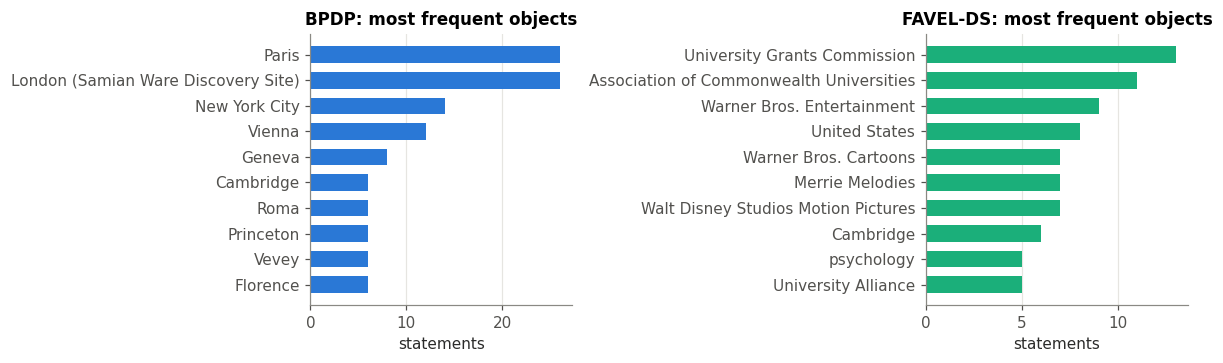

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, ds in zip(axes, MAIN):
    d = df[df.dataset == ds]
    top = Counter(d.object).most_common(10)[::-1]
    ax.barh([info[q]["label"] or q for q, _ in top], [n for _, n in top], color=C[ds], height=0.65)
    ax.set_title(f"{ds}: most frequent objects")
    ax.set_xlabel("statements")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "03_top_objects.png")
plt.show()

In **BPDP** every false statement is a true one with the predicate swapped: the person's place of death is given as the place of birth
and the other way round (e.g. A. E. van Vogt: born in Winnipeg = true, born in Hollywood = false). This is a hard and very specific
kind of negative, because both entities really are connected; only the relation is wrong.

In **FAVEL-DS** almost all false statements replace the object with another entity of a fitting type
(e.g. a different university or a different city), which is closer to the usual fact-checking setting. Train and test share many entities, which is worth keeping in mind for any approach that learns from the train split.

## 5. Wikipedia coverage

ShallKnow builds its text corpus from English Wikipedia, starting from the article of the subject and of the object.
An entity without an English article contributes no text at all.

In [13]:
cov_rows = []
for ds in MAIN:
    d = df[df.dataset == ds]
    ents = set(d.subject) | set(d.object)
    has = {q for q in ents if info[q]["enwiki"]}
    both = (d.subj_wiki.notna() & d.obj_wiki.notna())
    cov_rows.append({"dataset": ds, "entities": len(ents), "with enwiki article": len(has),
                     "coverage": f"{len(has) / len(ents):.1%}",
                     "statements with both articles": f"{both.mean():.1%}"})
coverage = pd.DataFrame(cov_rows).set_index("dataset")
coverage

,entities,with enwiki article,coverage,statements with both articles
dataset,,,,
BPDP,245,226,92.2%,79.8%
FAVEL-DS,1181,1154,97.7%,96.1%


In [14]:
# entities without an English article, by how many statements use them
uses = Counter((ds, q) for ds, s, o in zip(df.dataset, df.subject, df.object) for q in (s, o))
missing = pd.DataFrame([{"dataset": ds, "id": q, "label": info[q]["label"], "statements": n}
                        for (ds, q), n in uses.items() if not info[q]["enwiki"]])
missing = missing.sort_values("statements", ascending=False)
for ds in MAIN:
    m = missing[missing.dataset == ds]
    total = sum(n for (d, _), n in uses.items() if d == ds)
    print(f"{ds:9} entity mentions without an article: {m.statements.sum()} of {total} ({m.statements.sum() / total:.1%})")
missing.head(12)

BPDP      entity mentions without an article: 82 of 812 (10.1%)
FAVEL-DS  entity mentions without an article: 43 of 2184 (2.0%)


,dataset,id,label,statements
4,BPDP,Q103177460,London (Samian Ware Discovery Site),26
17,BPDP,Q12488329,Kabul,6
3,BPDP,Q18287233,Roma,6
29,FAVEL-DS,Q21713103,Cambridge,6
1,BPDP,Q21713103,Cambridge,6
16,BPDP,Q10314624,Kopenhagen,4
21,FAVEL-DS,Q103177460,London (Samian Ware Discovery Site),4
11,BPDP,Q109648820,Ikesankom,4
13,BPDP,Q11895558,Sydney,4
15,BPDP,Q103158107,Cádiz (Samian Ware Discovery Site),4


**Finding 2: part of the entity mapping is wrong.** The missing entities are not obscure places. They are London, Rome, Cambridge,
Sydney, Copenhagen, Cairo, Venice... mapped to the *wrong* Wikidata item, e.g. `Q103177460` is "London (Samian Ware Discovery Site)",
an archaeological record, not the city (26 BPDP statements use it). Labels like "Kopenhagen", "El Cairo" or "Roma" suggest that these
entities were matched by name in a non-English source. The benchmarks were originally built on DBpedia and mapped to Wikidata by the authors
with a fuzzy fallback (`scripts/db_to_wiki.py` in their repository), and this is where it fails. It affects about 10% of the entity mentions
in BPDP and 2% in FAVEL-DS. For such statements ShallKnow gets no text for one of the two entities, and a path-based fact checker looks for
paths to the wrong node in the graph.

## 6. Article size and the cost of the pipeline

The paragraph simplification step of ShallKnow (`wikipedia_extractor_final.py`) processes, for every **true** statement,
the subject article, the object article **and every article they link to**, with one LLM call per article
(articles already processed for another statement are skipped).
We measure article sizes for all entities and the number of outgoing links for a random sample of 60 entities per dataset.

In [15]:
titles = sorted({t for t in pd.concat([df.subj_wiki, df.obj_wiki]).dropna()})
lengths = article_lengths(titles)

random.seed(42)
link_sample = {}
for ds in MAIN:
    d = df[(df.dataset == ds) & (df.label == 1)]
    ents = sorted({t for t in pd.concat([d.subj_wiki, d.obj_wiki]).dropna()})
    link_sample[ds] = {t: outgoing_links(t) for t in random.sample(ents, min(60, len(ents)))}

for ds in MAIN:
    v = np.array(list(link_sample[ds].values()))
    print(f"{ds:9} links per article: median {np.median(v):.0f}, mean {v.mean():.0f}, max {v.max()}")

BPDP      links per article: median 508, mean 713, max 2722
FAVEL-DS  links per article: median 247, mean 390, max 1968


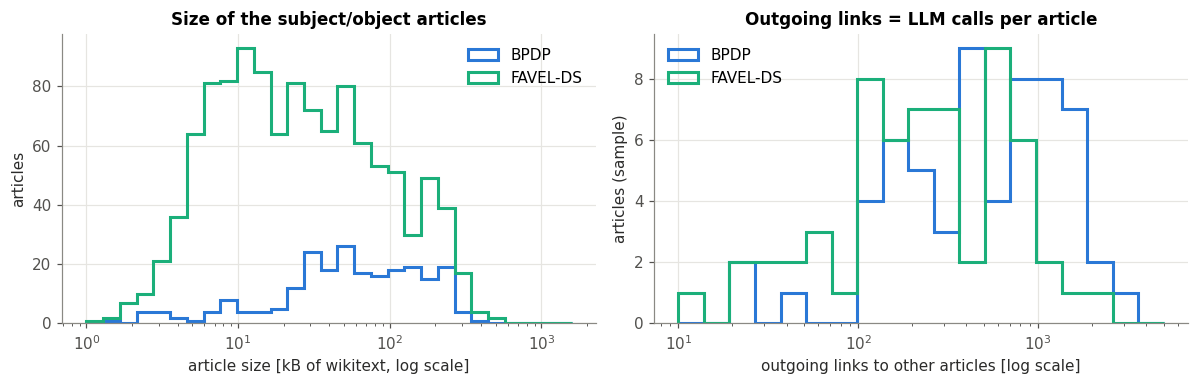

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ds in MAIN:
    d = df[df.dataset == ds]
    ts = sorted({t for t in pd.concat([d.subj_wiki, d.obj_wiki]).dropna()})
    kb = np.array([lengths[t] for t in ts if lengths.get(t)]) / 1000
    axes[0].hist(kb, bins=np.logspace(0, 3.2, 30), histtype="step", linewidth=2, color=C[ds], label=ds)
    axes[1].hist(list(link_sample[ds].values()), bins=np.logspace(1, 3.7, 20), histtype="step", linewidth=2, color=C[ds], label=ds)
axes[0].set_xscale("log"); axes[0].set_xlabel("article size [kB of wikitext, log scale]"); axes[0].set_ylabel("articles")
axes[0].set_title("Size of the subject/object articles")
axes[1].set_xscale("log"); axes[1].set_xlabel("outgoing links to other articles [log scale]"); axes[1].set_ylabel("articles (sample)")
axes[1].set_title("Outgoing links = LLM calls per article")
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(FIG / "04_article_size_links.png")
plt.show()

### How long would a full run take?

Upper bound: every true statement costs `2 + links(subject) + links(object)` calls (no article shared between statements).
Lower estimate: in the paper, ShallKnow processed roughly 350k articles for 3,238 entities, i.e. about **108 unique articles per entity**
after deduplication. For the time per call we use what we measured in our trial runs with `deepseek-r1:14b` (about 7 s per call on average,
3 to 17 s depending on the article length).

In [17]:
SEC_PER_CALL = 7
cost_rows = []
for ds in MAIN:
    d = df[(df.dataset == ds) & (df.label == 1)]
    mean_links = np.mean(list(link_sample[ds].values()))
    n_ent = len({t for t in pd.concat([d.subj_wiki, d.obj_wiki]).dropna()})
    upper = len(d) * (2 + 2 * mean_links)
    lower = n_ent * 108
    cost_rows.append({"dataset": ds, "true statements": len(d), "entities with article": n_ent,
                      "LLM calls (lower)": int(lower), "LLM calls (upper)": int(upper),
                      "hours (lower)": round(lower * SEC_PER_CALL / 3600), "hours (upper)": round(upper * SEC_PER_CALL / 3600)})
cost = pd.DataFrame(cost_rows).set_index("dataset")
cost

,true statements,entities with article,LLM calls (lower),LLM calls (upper),hours (lower),hours (upper)
dataset,,,,,,
BPDP,203,226,24408,289856,47,564
FAVEL-DS,543,770,83160,424879,162,826


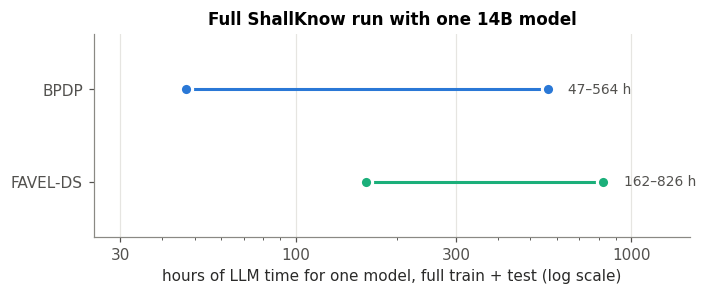

In [18]:
fig, ax = plt.subplots(figsize=(7, 2.4))
y = np.arange(len(cost))[::-1]
for yi, (ds, r) in zip(y, cost.iterrows()):
    ax.plot([r["hours (lower)"], r["hours (upper)"]], [yi, yi], color=C[ds], linewidth=2, solid_capstyle="round")
    ax.plot([r["hours (lower)"], r["hours (upper)"]], [yi, yi], "o", color=C[ds], markersize=8, markeredgecolor="white", markeredgewidth=2)
    ax.text(r["hours (upper)"] * 1.15, yi, f"{r['hours (lower)']}–{r['hours (upper)']} h", va="center", fontsize=9, color="#52514e")
ax.set_xscale("log")
ax.set_xticks([30, 100, 300, 1000], ["30", "100", "300", "1000"])
ax.set_xlim(25, 1500)
ax.set_yticks(y, cost.index)
ax.set_xlabel("hours of LLM time for one model, full train + test (log scale)")
ax.set_title("Full ShallKnow run with one 14B model")
ax.grid(axis="y", visible=False)
ax.set_ylim(-0.6, len(cost) - 0.4)
fig.savefig(FIG / "05_runtime_estimate.png")
plt.show()

**Finding 3: a full run is not feasible for us, so we will compare the models on a fixed subset.** Even the lower estimate is
hundreds of hours of LLM time per model on a shared GPU, and we want to compare about six models. We will therefore fix a random subset
of true statements and cap the number of linked articles per entity, and run *every* model on exactly the same input.

## 7. Is there textual evidence for the statements?

ShallKnow can only add knowledge that is written somewhere. As a cheap proxy we check whether the **subject's Wikipedia article
mentions the object** (by its English label or article title). We do this for all BPDP statements and for a random sample
of 200 FAVEL-DS statements (100 true, 100 false).

In [19]:
def names(q):
    out = set()
    if info[q]["label"]:
        out.add(info[q]["label"])
        out.add(re.sub(r"\s*\(.*\)$", "", info[q]["label"]))
    if info[q]["enwiki"]:
        t = info[q]["enwiki"]
        out.add(t)
        out.add(re.sub(r"\s*\(.*\)$", "", t))   # "Gela (river)" -> "Gela"
        out.add(t.split(",")[0])                 # "Princeton, New Jersey" -> "Princeton"
    return {n for n in out if len(n) > 2}


ev = pd.concat([
    df[df.dataset == "BPDP"],
    df[(df.dataset == "FAVEL-DS") & (df.label == 1)].sample(100, random_state=1),
    df[(df.dataset == "FAVEL-DS") & (df.label == 0)].sample(100, random_state=1),
])
ev = ev[ev.subj_wiki.notna()].copy()
ev["object_mentioned"] = [any(n in article_text(s) for n in names(o)) for s, o in zip(ev.subj_wiki, ev.object)]
evidence = ev.groupby(["dataset", "label"]).object_mentioned.mean().unstack()
evidence.columns = ["false", "true"]
evidence.round(2)

,false,true
dataset,,
BPDP,0.85,0.85
FAVEL-DS,0.73,0.68


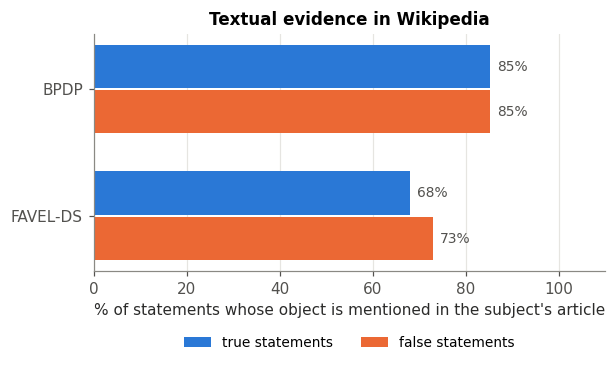

In [20]:
fig, ax = plt.subplots(figsize=(6, 2.8))
y = np.arange(len(evidence))[::-1]
ax.barh(y + 0.18, evidence["true"] * 100, height=0.34, color=C_TRUE, label="true statements")
ax.barh(y - 0.18, evidence["false"] * 100, height=0.34, color=C_FALSE, label="false statements")
for yi, (_, r) in zip(y, evidence.iterrows()):
    ax.text(r["true"] * 100 + 1.5, yi + 0.18, f"{r['true']:.0%}", va="center", fontsize=9, color="#52514e")
    ax.text(r["false"] * 100 + 1.5, yi - 0.18, f"{r['false']:.0%}", va="center", fontsize=9, color="#52514e")
ax.set_yticks(y, evidence.index)
ax.set_xlim(0, 110)
ax.set_xlabel("% of statements whose object is mentioned in the subject's article")
ax.set_title("Textual evidence in Wikipedia")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=9)
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "06_textual_evidence.png")
plt.show()

In [21]:
# BPDP true statements where the subject's article does not mention the object at all
noev = ev[(ev.dataset == "BPDP") & (ev.label == 1) & (~ev.object_mentioned)]
noev[["subj_label", "pred_label", "obj_label"]].head(10)

,subj_label,pred_label,obj_label
17,Frédéric Bastiat,place of death (P20),Roma
23,Fay Wray,place of death (P20),New York City
27,Henry Moseley,place of death (P20),Gelibolu district
38,Arthur de Gobineau,place of death (P20),Turin
40,André Weil,place of death (P20),Princeton
42,Catherine of Aragon,place of death (P20),Huntingdonshire
52,James Clavell,place of death (P20),Vevey
125,Ernst Mayr,place of birth (P19),Kempten
132,Carlo Goldoni,place of birth (P19),Venezia
133,Joe Strummer,place of birth (P19),Ankara Province


**Finding 4: co-occurrence in the text hardly separates true from false.** Because the false BPDP statements only swap birth and
death place, the object is mentioned in the subject's article exactly as often for false statements as for true ones. In FAVEL-DS the
object of a *false* statement is mentioned about as often as for a true one, because the replacement objects are entities of the
same type that are related to the subject (a university where the person studied instead of the one where they worked, etc.).
So mentioning is not enough; the *relation* has to be extracted correctly, which is exactly the job of the LLM in ShallKnow
(and the part we want to replace with smaller models).

Some "true" labels are questionable. For example the dataset says A. E. van Vogt was **born** in Winnipeg, but Wikipedia says he
was born in Edenburg, Manitoba, and moved to Winnipeg for high school. Such label noise puts a ceiling on what any fact checker can reach.

## 8. Summary

| | BPDP | FAVEL-DS | FactBench |
|---|---|---|---|
| file usable | yes | yes | no, ~50% of the statements are merged |
| statements (train/test) | 200 / 206 | 765 / 327 | 1119 / 1129 in the paper |
| relations | 2 | 11 | 9 |
| false statements made by | swapping birth/death place | replacing the object | n/a |
| entity mentions without an enwiki article (mostly wrong Wikidata ids) | ~10% | ~2% | n/a |

* We use **FAVEL-DS** as the main dataset and **BPDP** for quick tests. FactBench is excluded because the published files are corrupted.
* Most entities have an English Wikipedia article, but some were mapped to the wrong Wikidata item (London, Rome, Cambridge, ...),
  mostly in BPDP. We keep the data as published, to stay comparable with the paper, and report this as a limitation.
* The pipeline needs one LLM call per linked article; a full run with one model would take hundreds of hours on our hardware.
  All models will therefore be compared on the **same fixed subset** of statements with a cap on linked articles.
* BPDP is hard by construction (only the relation is wrong) and contains some questionable labels, so improvements there will be small,
  in line with the paper (at most +0.04 AUROC on BPDP).

In [22]:
# numbers used by the charts in dashboard/
summary = {
    "integrity": [{"name": f"{ds} {split}", "clean": int(raw[(raw.dataset == ds) & (raw.split == split)].clean.sum()),
                   "merged": int((~raw[(raw.dataset == ds) & (raw.split == split)].clean).sum())} for ds, split in FILES],
    "predicates": {ds: [{"name": k.split(" (")[0], "true": int(v[1]), "false": int(v[0])}
                        for k, v in pred_stats[ds].iloc[::-1].iterrows()] for ds in MAIN},
    "corruption": {ds: {k: int(v) for k, v in corr_df[ds].items() if v} for ds in MAIN},
    "coverage": {ds: float(coverage.loc[ds, "with enwiki article"] / coverage.loc[ds, "entities"]) for ds in MAIN},
    "links": {ds: sorted(int(x) for x in link_sample[ds].values()) for ds in MAIN},
    "cost": {ds: {k: int(v) for k, v in cost.loc[ds].items()} for ds in MAIN},
    "evidence": {ds: {"true": float(evidence.loc[ds, "true"]), "false": float(evidence.loc[ds, "false"])} for ds in MAIN},
}
out = ROOT / "dashboard" / "src" / "data"
out.mkdir(parents=True, exist_ok=True)
(out / "eda_summary.json").write_text(json.dumps(summary, indent=1))

3318